## 5. Explicabilidade Visual (Grad-CAM)

Num contexto clínico de referenciação hospitalar , a interpretabilidade do modelo é um fator crítico de sucesso. O Grad-CAM (Gradient-weighted Class Activation Mapping) permite-nos visualizar em que regiões espaciais da imagem oftalmológica a Convolutional Neural Network (CNN) se focou para tomar a sua decisão.

Esta análise permite-nos validar se o modelo está a aprender a identificar características patológicas reais (como exsudatos duros na retinopatia diabética ou opacidade na lente na catarata) em vez de focar em ruído ou em artefactos irrelevantes presentes nas imagens.

In [8]:
# Importacoes -- Explicabilidade / Grad-CAM (CPU local; usa TensorFlow para
# carregar os modelos .keras).
from pathlib import Path
import os, random, sys
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import load_model


In [9]:
# Google colab check: Bootstrap - deteta Colab vs local, monta o Drive se necessario e coloca o repo
# no sys.path. 
try:
    import google.colab  # noqa: F401
    from google.colab import drive
    drive.mount('/content/drive')
    REPO_ROOT = Path('/content/drive/MyDrive/ophthalmic-referral-cnn')
except ImportError:
    REPO_ROOT = Path.cwd()
    while not (REPO_ROOT / 'src').is_dir():
        if REPO_ROOT.parent == REPO_ROOT:
            raise RuntimeError("Repo root not found — no 'src' directory above cwd")
        REPO_ROOT = REPO_ROOT.parent

sys.path.insert(0, str(REPO_ROOT))

from src import bootstrap, data, viz

IN_COLAB = bootstrap.setup()
REPO_DIR = bootstrap.get_repo_dir(IN_COLAB)
DATA_DIR = REPO_ROOT
print("DATA_DIR:", DATA_DIR)
print("contents:", os.listdir(DATA_DIR))
base_dir = str(DATA_DIR)



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_DIR: /content/drive/MyDrive/ophthalmic-referral-cnn
contents: ['Deep_Learning_Base.ipynb', 'notebooks', 'src', 'ocular', 'artifacts']


In [10]:
# Reprodutibilidade: sementes fixas em todas as fontes de aleatoriedade.
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)


In [11]:
# Carregamento do dataset (mesma ordem determinista de src/data.py).
X_original, y, nomes_ficheiros, labels_ficheiros, folders = data.load_dataset(DATA_DIR)
print("X_original:", X_original.shape, "| y:", y.shape)


X_original: (2570, 224, 224, 3) | y: (2570,)


In [5]:
# Diretorios de artefactos -- sempre em Drive (derivam de REPO_DIR).
ARTIFACT_DIRS = bootstrap.get_artifact_dirs(REPO_DIR)
ARTIFACTS_DIR = ARTIFACT_DIRS["artifacts"]
MODELS_DIR    = ARTIFACT_DIRS["models"]
PREDS_DIR     = ARTIFACT_DIRS["preds"]
HISTORY_DIR   = ARTIFACT_DIRS["history"]
for _d in (MODELS_DIR, PREDS_DIR, HISTORY_DIR):
    _d.mkdir(parents=True, exist_ok=True)
print("Artefactos em:", ARTIFACTS_DIR)


Artefactos em: /content/drive/MyDrive/ophthalmic-referral-cnn/artifacts


In [6]:
# Reconstrucao do conjunto de teste a partir do split committed. Duas escalas:
# [0,1] para a CNN de raiz, [0,255] para os modelos de transfer learning.
split = data.load_split_indices(ARTIFACTS_DIR / "split_indices.npz")
test_idx = split["test_idx"]
y = y.astype(int)
y_test = y[test_idx]
X_test    = (X_original.astype("float32") / 255.0)[test_idx]   # CNN de raiz: [0,1]
X_test_tl = X_original[test_idx].astype("float32")             # transfer learning: [0,255]
class_names = data.CLASS_NAMES


In [7]:
# Modelos carregados de artifacts/models/*.keras. ATENCAO: *.keras esta gitignored
# -- este notebook corre localmente com os modelos presentes (copiados do Drive),
# nao a partir do git apenas. Nomes de ficheiro seguem data.slug(nome).
model_regularized = load_model(MODELS_DIR / f"{data.slug('Regularizado')}.keras")
model_effnet = load_model(MODELS_DIR / f"{data.slug('EfficientNetB0 (fine-tuned)')}.keras")
model_resnet = load_model(MODELS_DIR / f"{data.slug('ResNet50 (fine-tuned)')}.keras")

# Grad-CAM em modelos Functional (TL) precisa do sub-modelo base convolucional.
# RISCO (ver BATCH_2_REPORT): os nomes das camadas base ('efficientnetb0' /
# 'resnet50') e das ultimas conv ('top_conv' / 'conv5_block3_out' / 'conv2d_2')
# dependem da estrutura gravada -- confirmar na sessao GPU.
base_model = model_effnet.get_layer("efficientnetb0")
base_model_resnet = model_resnet.get_layer("resnet50")


ValueError: Requested the deserialization of a `Lambda` layer whose `function` is a Python lambda. This carries a potential risk of arbitrary code execution and thus it is disallowed by default. If you trust the source of the artifact, you can override this error by passing `safe_mode=False` to the loading function, or calling `keras.config.enable_unsafe_deserialization().

Regularizado — Cataract


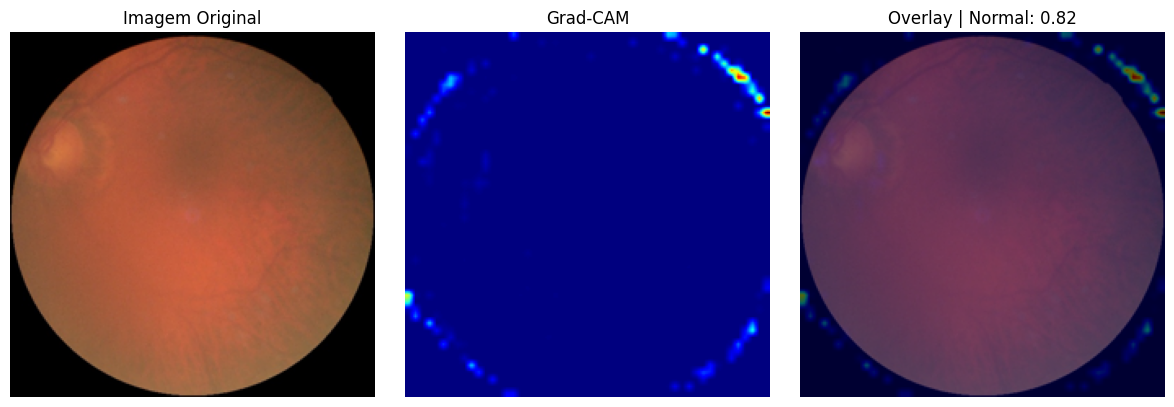

Regularizado — Diabetic


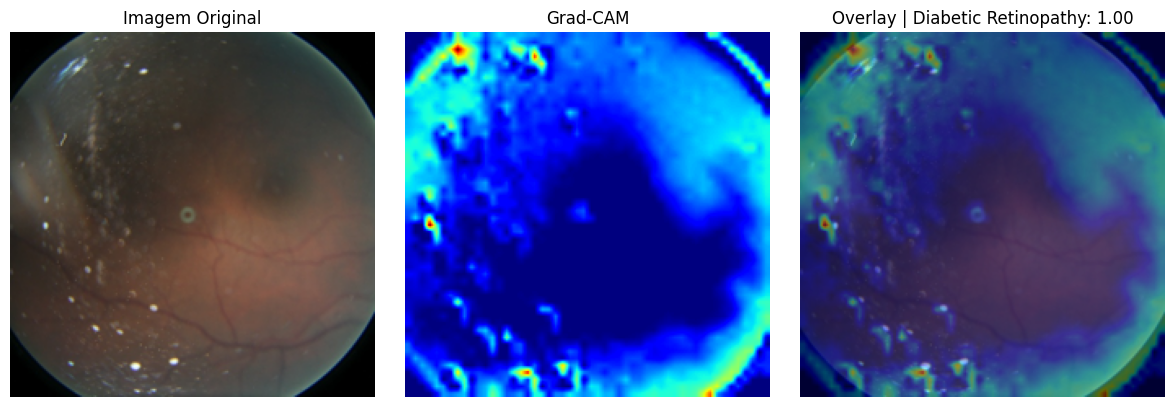

Regularizado — Normal


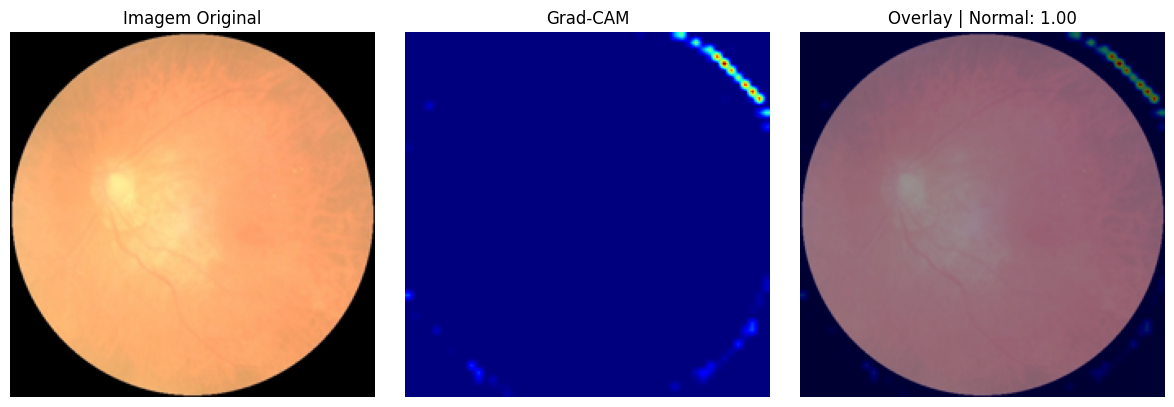

EfficientNetB0 — Cataract


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


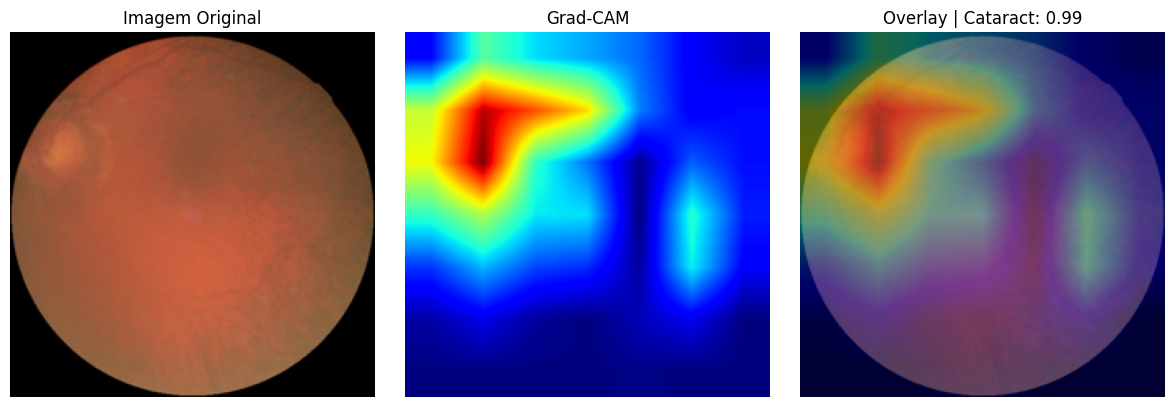

EfficientNetB0 — Diabetic


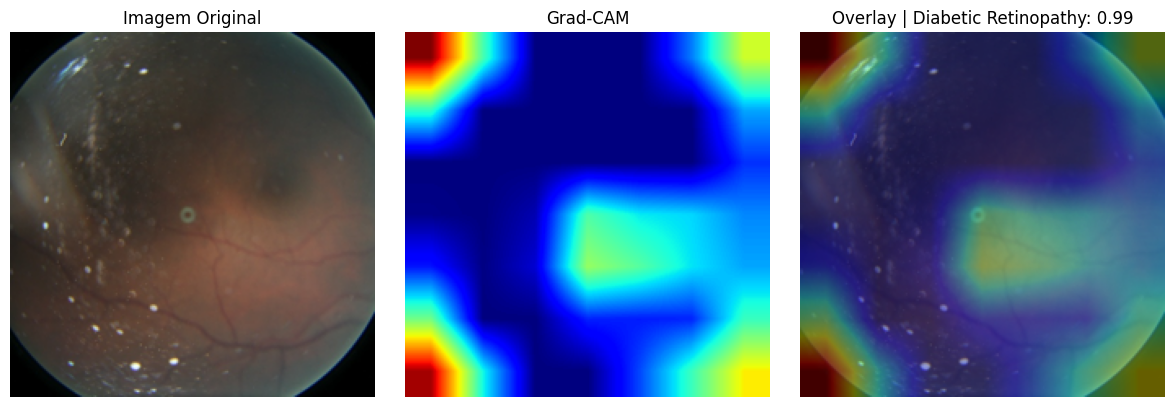

EfficientNetB0 — Normal


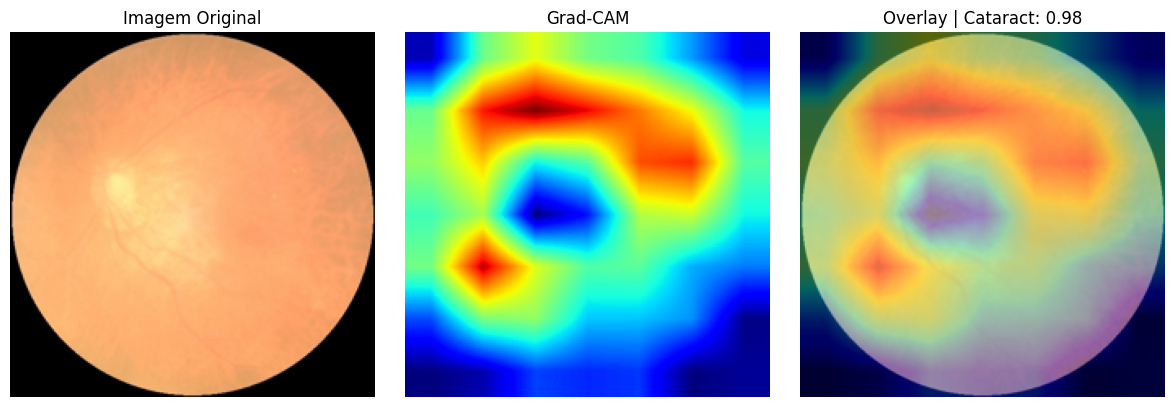

ResNet50 — Cataract


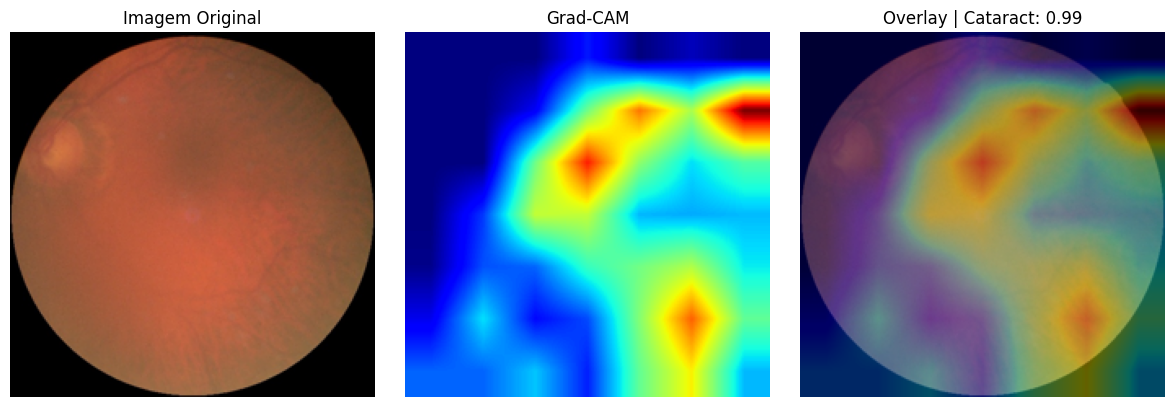

ResNet50 — Diabetic


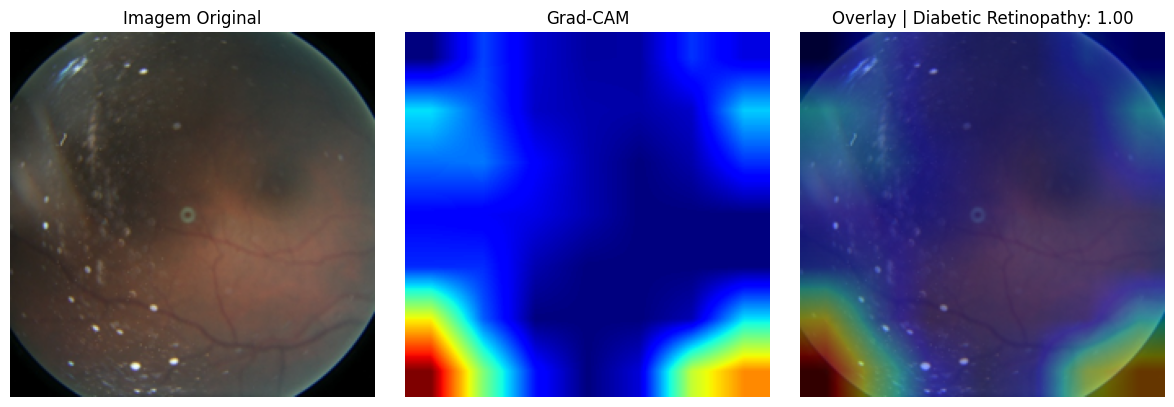

ResNet50 — Normal


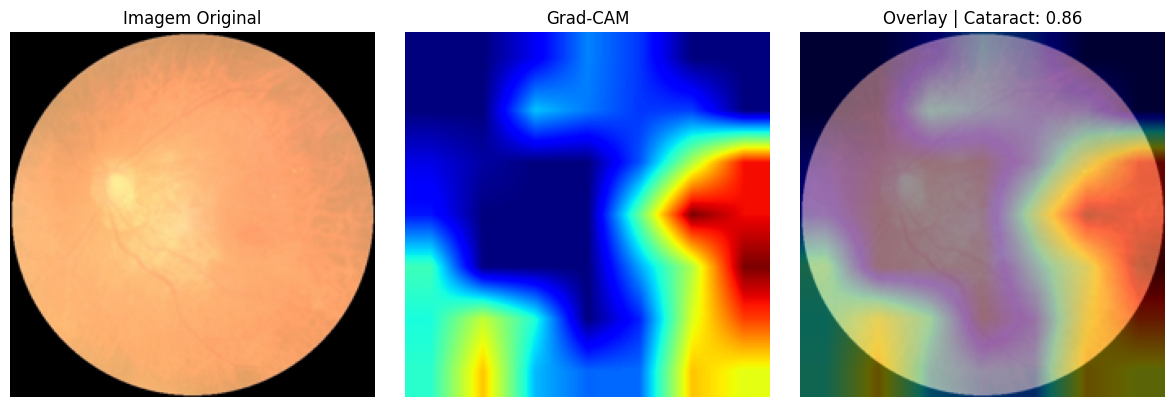

In [45]:
# índices de exemplo por classe no conjunto de teste

idx_cataract  = np.where(y_test == 0)[0][0]
idx_diabetic  = np.where(y_test == 1)[0][0]
idx_normal    = np.where(y_test == 2)[0][0]

# CNN Regularizado

for idx, cls in [(idx_cataract, "Cataract"), (idx_diabetic, "Diabetic"), (idx_normal, "Normal")]:
    print(f"Regularizado — {cls}")
    viz.show_grad_cam(model_regularized, X_test[idx], class_names, "conv2d_2")

# EfficientNetB0 fine-tuned

for idx, cls in [(idx_cataract, "Cataract"), (idx_diabetic, "Diabetic"), (idx_normal, "Normal")]:
    print(f"EfficientNetB0 — {cls}")
    viz.show_grad_cam(model_effnet, X_test_tl[idx], class_names, "top_conv", base_model=base_model)

# ResNet50 fine-tuned

for idx, cls in [(idx_cataract, "Cataract"), (idx_diabetic, "Diabetic"), (idx_normal, "Normal")]:
    print(f"ResNet50 — {cls}")
    viz.show_grad_cam(model_resnet, X_test_tl[idx], class_names, "conv5_block3_out", base_model=base_model_resnet)

## Grad-CAM sobre Falsos Positivos / Falsos Negativos / baixa confianca

*Placeholder de um batch posterior -- sem conteudo nesta fase.*
